In [4]:
import pandas as pd
import numpy as np
from scipy.io import arff
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data, meta = arff.loadarff("bone-marrow.arff")
df = pd.DataFrame(data)

for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].str.decode("utf-8")

df = df.replace("?", np.nan)

In [6]:
df.shape

(187, 37)

In [7]:
df.head()

,Recipientgender,Stemcellsource,Donorage,Donorage35,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,ABOmatch,...,extcGvHD,CD34kgx10d6,CD3dCD34,CD3dkgx10d8,Rbodymass,ANCrecovery,PLTrecovery,time_to_aGvHD_III_IV,survival_time,survival_status
0,1,1,22.830137,0,1,0,1,1,1,0,...,1,7.20,1.338760,5.38,35.0,19.0,51.0,32.0,999.0,0.0
1,1,0,23.342466,0,1,0,-1,-1,1,0,...,1,4.50,11.078295,0.41,20.6,16.0,37.0,1000000.0,163.0,1.0
2,1,0,26.394521,0,1,0,-1,-1,1,0,...,1,7.94,19.013230,0.42,23.4,23.0,20.0,1000000.0,435.0,1.0
3,0,0,39.684932,1,1,0,1,2,1,1,...,NaN,4.25,29.481647,0.14,50.0,23.0,29.0,19.0,53.0,1.0
4,0,1,33.358904,0,0,0,1,2,0,1,...,1,51.85,3.972255,13.05,9.0,14.0,14.0,1000000.0,2043.0,0.0


In [8]:
column_meanings = {
    'Recipientgender': 'Recipient gender',
    'Donorage': 'Donor age at cell collection',
    'Recipientage': 'Recipient age at transplant',
    'Rbodymass': 'Recipient body mass',
    'Gendermatch': 'Donor-recipient gender match',
    'Stemcellsource': 'Stem cell source (blood or marrow)',
    'Disease': 'Disease type (ALL, AML, chronic...)',
    'Diseasegroup': 'Malignant vs nonmalignant',
    'Riskgroup': 'Risk group (high or low)',
    'Txpostrelapse': 'Second transplant after relapse',
    'DonorABO': 'Donor ABO blood group',
    'RecipientABO': 'Recipient ABO blood group',
    'ABOmatch': 'ABO blood group match',
    'RecipientRh': 'Recipient Rh factor',
    'CMVstatus': 'Donor-recipient CMV compatibility',
    'DonorCMV': 'Donor CMV infection (prior)',
    'RecipientCMV': 'Recipient CMV infection (prior)',
    'HLAmatch': 'Tissue-type (HLA) match',
    'HLAmismatch': 'HLA mismatch (yes/no)',
    'Antigen': 'HLA antigen differences',
    'Alel': 'HLA allele differences',
    'HLAgrI': 'HLA difference type',
    'CD34kgx10d6': 'CD34+ stem cell dose',
    'CD3dkgx10d8': 'CD3+ immune cell dose',
    'CD3dCD34': 'CD3+ to CD34+ ratio',
    'ANCrecovery': 'Neutrophil (ANC) recovery time',
    'PLTrecovery': 'Platelet recovery time',
    'IIIV': 'Acute graft-vs-host disease (stage II-IV)',
    'aGvHDIIIIV': 'Acute graft-vs-host disease (stage III-IV)',
    'extcGvHD': 'Extensive chronic graft-vs-host disease',
    'time_to_aGvHD_III_IV': 'Time to severe acute GvHD',
    'Relapse': 'Disease relapse',
    'survival_time': 'Survival time (days) — regression target',
    'survival_status': 'Alive or died — classification target',
    'ANC_recovered': 'Whether ANC recovery ever happened',
    'PLT_recovered': 'Whether platelet recovery ever happened',
    'aGvHD_occurred': 'Whether severe acute GvHD ever happened',
}

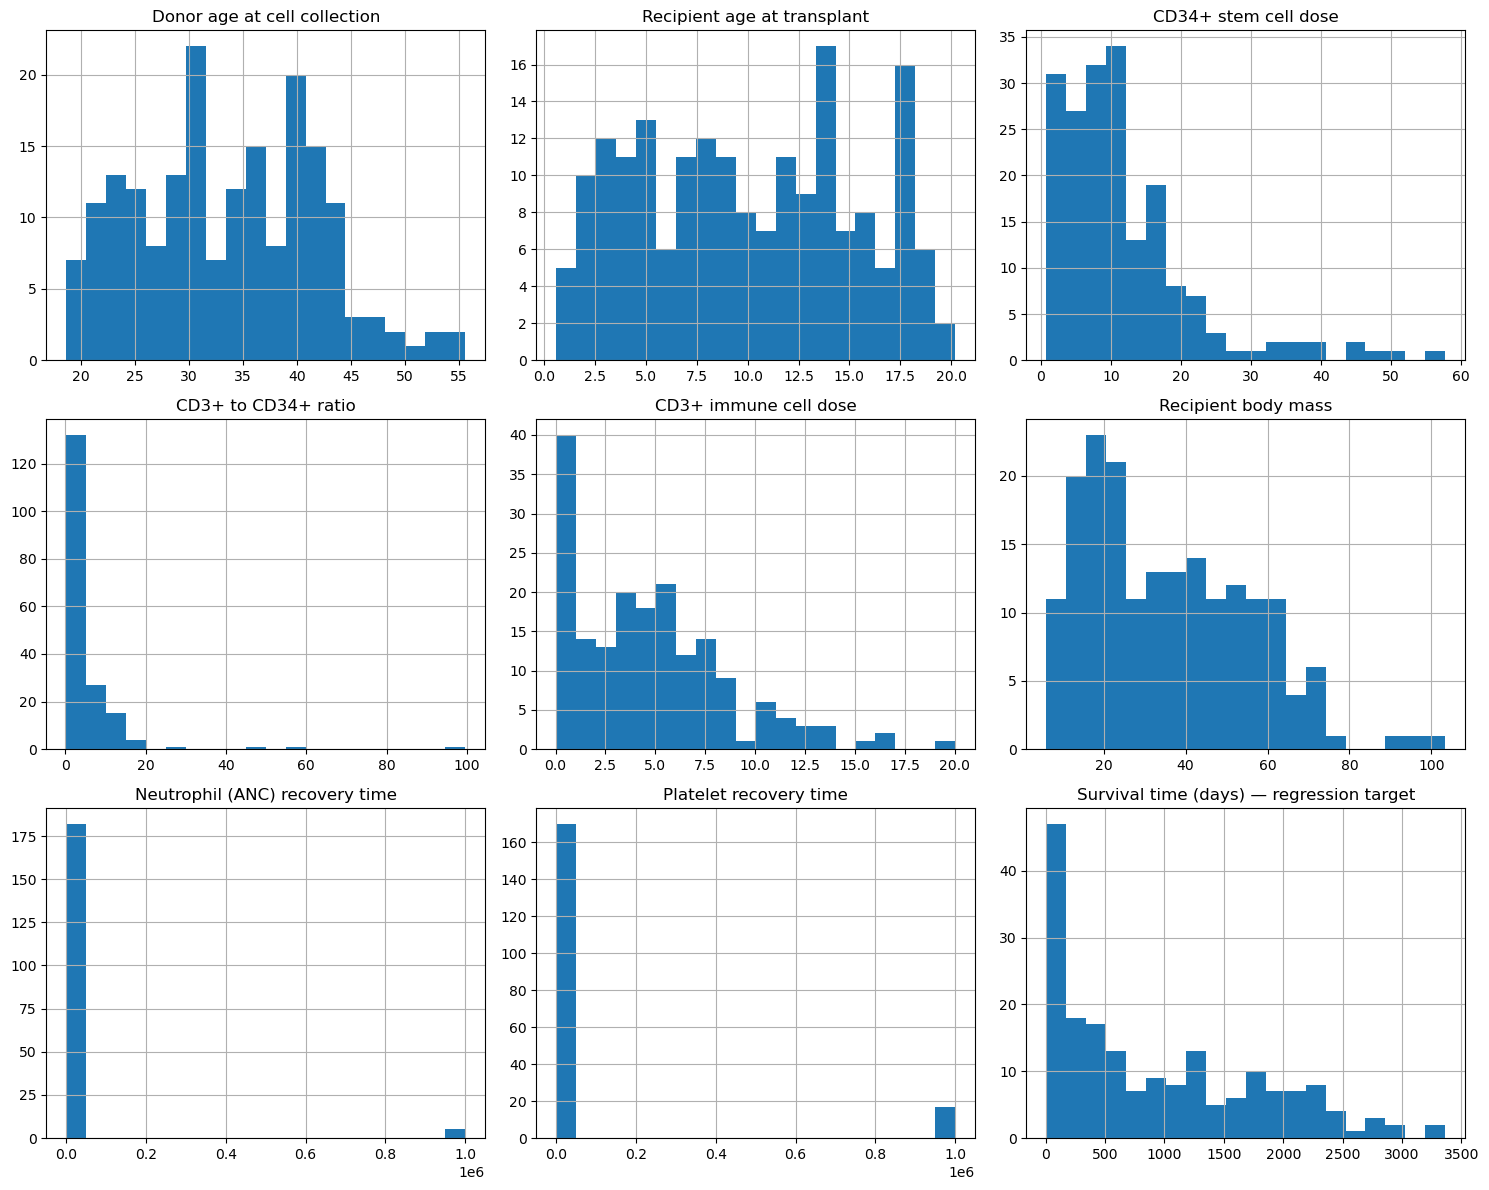

In [9]:
num_cols = ['Donorage','Recipientage','CD34kgx10d6','CD3dCD34','CD3dkgx10d8',
            'Rbodymass','ANCrecovery','PLTrecovery','survival_time']

for c in num_cols:
    df[c] = pd.to_numeric(df[c])

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, c in zip(axes.flat, num_cols):
    df[c].hist(ax=ax, bins=20)
    ax.set_title(column_meanings.get(c, c))
plt.tight_layout()
plt.show()

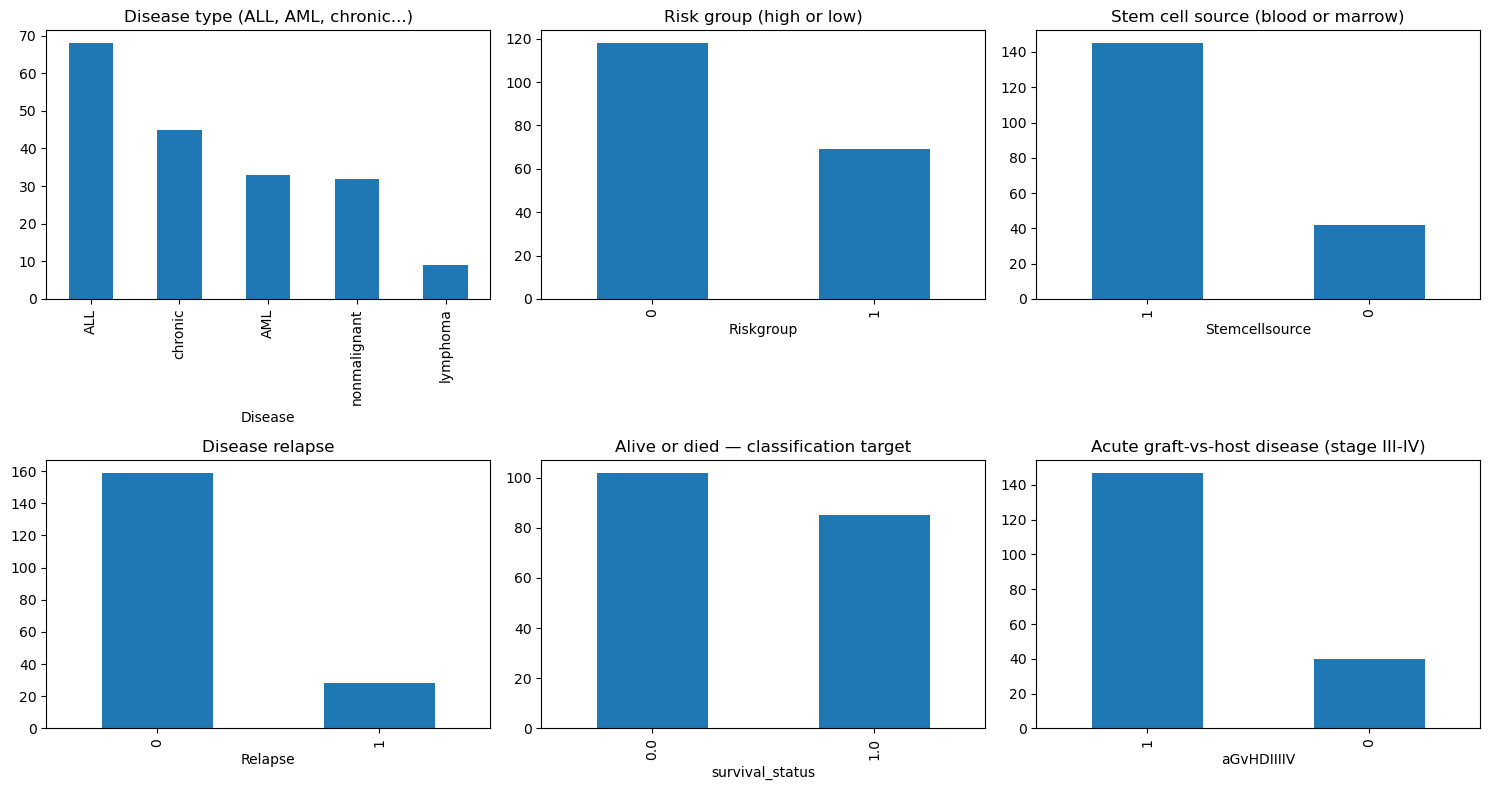

In [10]:
cat_cols = ['Disease', 'Riskgroup', 'Stemcellsource', 'Relapse', 'survival_status', 'aGvHDIIIIV']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cat_cols):
    df[c].value_counts(dropna=False).plot(kind='bar', ax=ax)
    ax.set_title(column_meanings.get(c, c))
plt.tight_layout()
plt.show()

survival_status
0.0    0.545455
1.0    0.454545
Name: proportion, dtype: float64


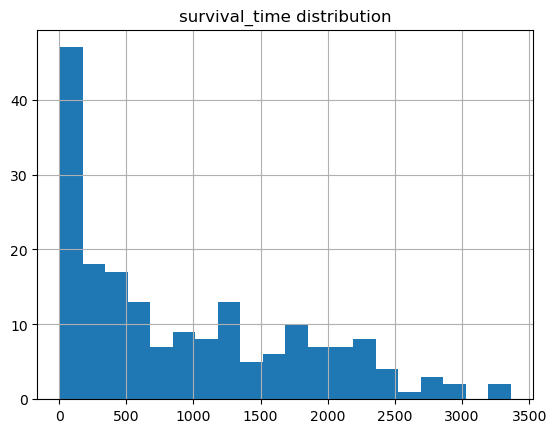

In [11]:
print(df['survival_status'].value_counts(normalize=True))
df['survival_time'].hist(bins=20)
plt.title("survival_time distribution")
plt.show()

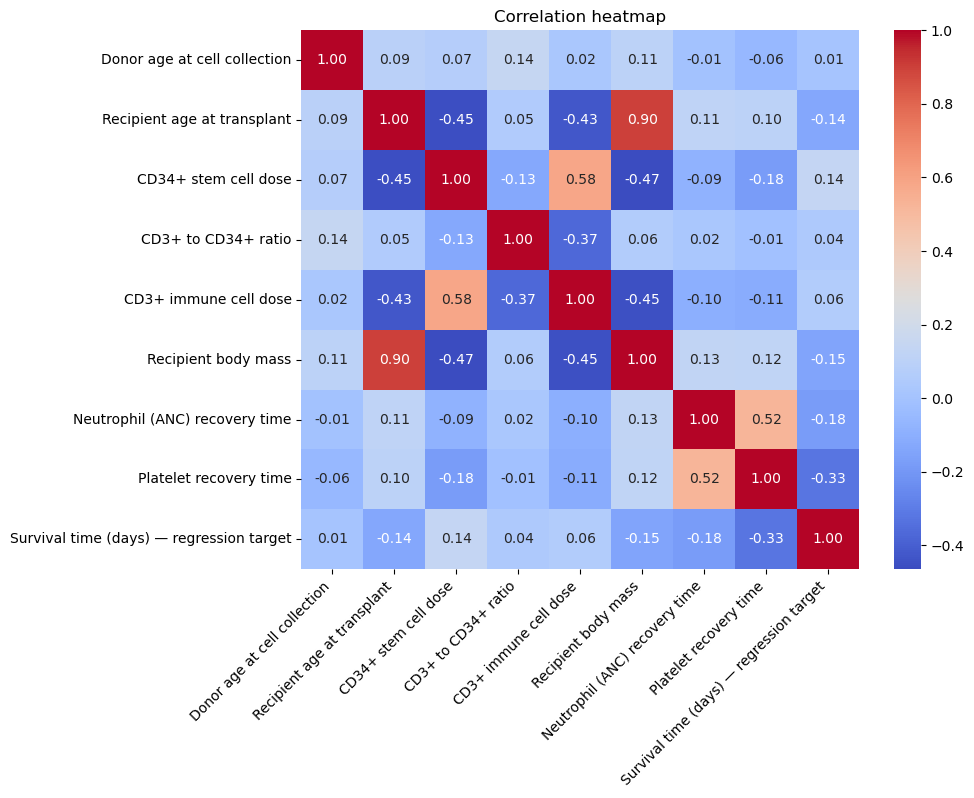

In [12]:
plt.figure(figsize=(9, 7))
corr = df[num_cols].corr()
corr = corr.rename(index=column_meanings, columns=column_meanings)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.xticks(rotation=45, ha='right')
plt.show()

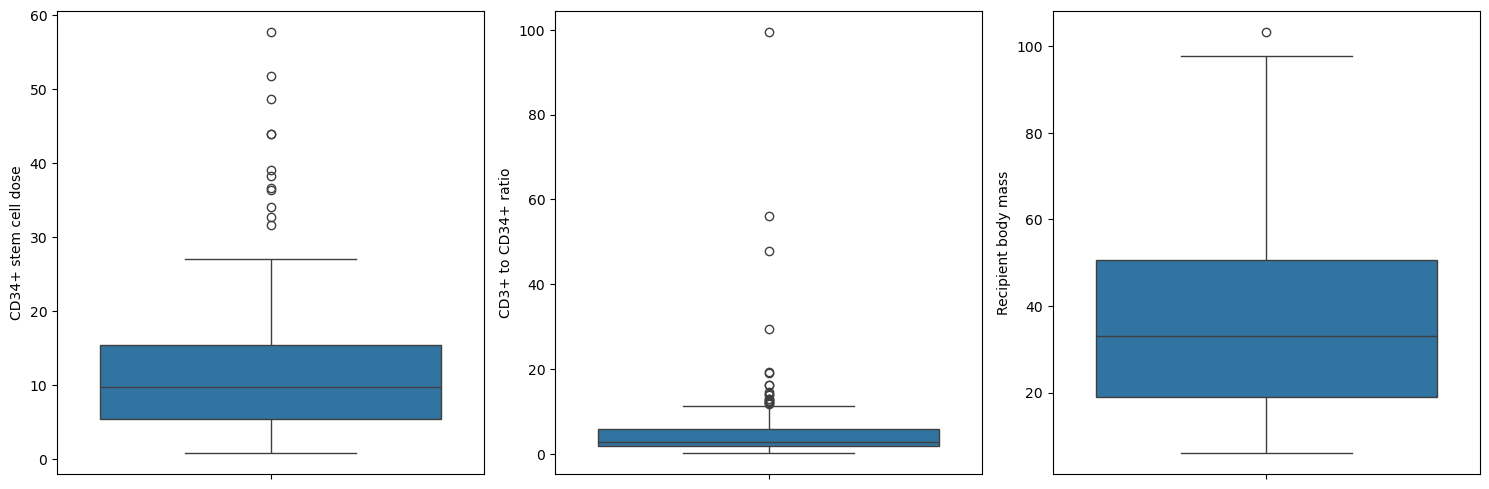

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.boxplot(y=df['CD34kgx10d6'], ax=axes[0])
sns.boxplot(y=df['CD3dCD34'], ax=axes[1])
sns.boxplot(y=df['Rbodymass'], ax=axes[2])
axes[0].set_ylabel(column_meanings.get('CD34kgx10d6', 'CD34kgx10d6'))
axes[1].set_ylabel(column_meanings.get('CD3dCD34', 'CD3dCD34'))
axes[2].set_ylabel(column_meanings.get('Rbodymass', 'Rbodymass'))
plt.tight_layout()
plt.show()

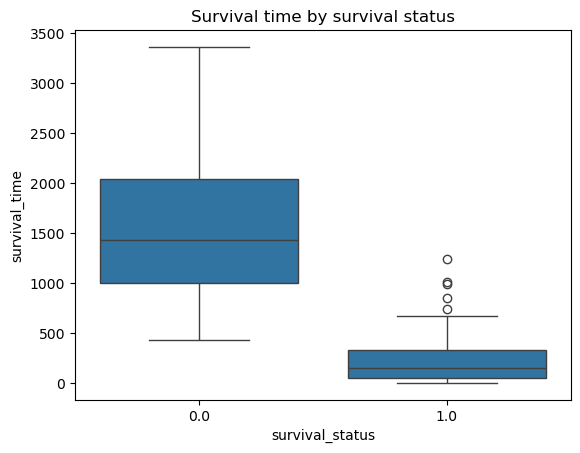

survival_status  0.0  1.0
Disease                  
ALL               38   30
AML               18   15
chronic           26   19
lymphoma           0    9
nonmalignant      20   12
Relapse      0   1
Riskgroup         
0          106  12
1           53  16


In [16]:
sns.boxplot(x='survival_status', y='survival_time', data=df)
plt.title("Survival time by survival status")
plt.show()

print(pd.crosstab(df['Disease'], df['survival_status']))
print(pd.crosstab(df['Riskgroup'], df['Relapse']))


In [17]:
print(df.duplicated().sum())

0


In [18]:
coded_cols = [c for c in df.columns if str(df[c].dtype) == 'str' and c != 'Disease']
for c in coded_cols:
    df[c] = pd.to_numeric(df[c]).astype('Int64')

df['survival_status'] = df['survival_status'].astype(int)
print(df.dtypes.value_counts())


object     26
float64    10
int64       1
Name: count, dtype: int64


In [19]:
df['ANC_recovered']   = (df['ANCrecovery'] != 1000000).astype(int)
df['PLT_recovered']   = (df['PLTrecovery'] != 1000000).astype(int)
df['aGvHD_occurred']  = (df['time_to_aGvHD_III_IV'] != 1000000).astype(int)

df.loc[df['ANCrecovery'] == 1000000, 'ANCrecovery'] = np.nan
df.loc[df['PLTrecovery'] == 1000000, 'PLTrecovery'] = np.nan
df.loc[df['time_to_aGvHD_III_IV'] == 1000000, 'time_to_aGvHD_III_IV'] = np.nan

print(df['ANCrecovery'].describe())

count    182.000000
mean      15.307692
std        3.010818
min        9.000000
25%       13.000000
50%       15.000000
75%       17.000000
max       26.000000
Name: ANCrecovery, dtype: float64


In [20]:
df = df.drop(columns=['Donorage35', 'Recipientage10', 'Recipientageint'])
print(df.shape)

(187, 37)


In [22]:
print(df.shape)
print(df.dtypes.value_counts())
print(df.isna().sum()[df.isna().sum() > 0])

(187, 37)
object     23
float64    10
int64       4
Name: count, dtype: int64
RecipientABO              1
RecipientRh               2
ABOmatch                  1
CMVstatus                16
DonorCMV                  2
RecipientCMV             14
Antigen                   1
Alel                      1
extcGvHD                 31
CD3dCD34                  5
CD3dkgx10d8               5
Rbodymass                 2
ANCrecovery               5
PLTrecovery              17
time_to_aGvHD_III_IV    145
dtype: int64


In [23]:
print(df['survival_status'].value_counts())
print(df['survival_status'].value_counts(normalize=True).round(3))


survival_status
0    102
1     85
Name: count, dtype: int64
survival_status
0    0.545
1    0.455
Name: proportion, dtype: float64


In [24]:
df_cls = pd.get_dummies(df, columns=['Disease'], prefix='Disease')

y = df_cls['survival_status']
X = df_cls.drop(columns=['survival_status', 'survival_time'])

print(X.shape, y.shape)

(187, 39) (187,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(149, 39) (38, 39)


In [26]:
from sklearn.impute import SimpleImputer

num_impute_cols = ['Donorage','Recipientage','CD34kgx10d6','CD3dCD34','CD3dkgx10d8',
                    'Rbodymass','ANCrecovery','PLTrecovery','time_to_aGvHD_III_IV']
cat_impute_cols = ['RecipientABO','RecipientRh','ABOmatch','CMVstatus','DonorCMV',
                    'RecipientCMV','Antigen','Alel','extcGvHD']

num_imputer = SimpleImputer(strategy='median')
X_train[num_impute_cols] = num_imputer.fit_transform(X_train[num_impute_cols])
X_test[num_impute_cols] = num_imputer.transform(X_test[num_impute_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[cat_impute_cols] = cat_imputer.fit_transform(X_train[cat_impute_cols])
X_test[cat_impute_cols] = cat_imputer.transform(X_test[cat_impute_cols])

print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_impute_cols] = scaler.fit_transform(X_train[num_impute_cols])
X_test_scaled[num_impute_cols] = scaler.transform(X_test[num_impute_cols])

In [30]:
print(X_train_scaled[num_impute_cols].describe().loc[['mean','std']].round(2))

      Donorage  Recipientage  CD34kgx10d6  CD3dCD34  CD3dkgx10d8  Rbodymass  \
mean       0.0          -0.0          0.0       0.0         -0.0       -0.0   
std        1.0           1.0          1.0       1.0          1.0        1.0   

      ANCrecovery  PLTrecovery  time_to_aGvHD_III_IV  
mean         -0.0         -0.0                   0.0  
std           1.0          1.0                   1.0  


In [31]:
X_train_scaled.head()

,Recipientgender,Stemcellsource,Donorage,IIIV,Gendermatch,DonorABO,RecipientABO,RecipientRh,ABOmatch,CMVstatus,...,PLTrecovery,time_to_aGvHD_III_IV,ANC_recovered,PLT_recovered,aGvHD_occurred,Disease_ALL,Disease_AML,Disease_chronic,Disease_lymphoma,Disease_nonmalignant
21,1,1,1.007457,1,0,-1,2,1,1,2,...,-0.355184,-0.187518,1,1,0,False,False,False,False,True
101,1,1,0.757162,0,1,-1,1,1,1,3,...,-0.381075,-0.187518,1,1,0,False,False,False,False,True
15,1,0,0.858288,0,0,0,-1,1,1,3,...,-0.329292,-0.187518,1,1,0,False,False,True,False,False
14,1,1,-0.427791,1,0,1,1,1,0,0,...,-0.406967,-0.187518,1,1,0,False,True,False,False,False
179,1,0,-0.507751,1,1,1,2,0,1,0,...,1.767925,-0.187518,1,1,0,True,False,False,False,False


In [32]:
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression(max_iter=1000, random_state=42)
model1.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [34]:
y_pred1 = model1.predict(X_test_scaled)
y_proba1 = model1.predict_proba(X_test_scaled)[:, 1]

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

acc = accuracy_score(y_test, y_pred1)
prec = precision_score(y_test, y_pred1)
rec = recall_score(y_test, y_pred1)
f1 = f1_score(y_test, y_pred1)
auc = roc_auc_score(y_test, y_proba1)

print(f"Accuracy: {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall: {rec:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"ROC-AUC: {auc:.3f}")

Accuracy: 0.553
Precision: 0.500
Recall: 0.412
F1-score: 0.452
ROC-AUC: 0.521


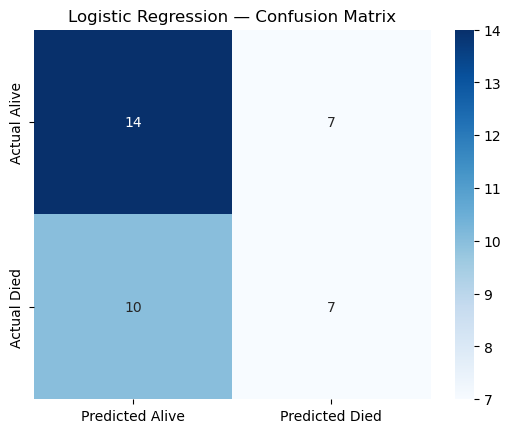

In [36]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Alive','Predicted Died'],
            yticklabels=['Actual Alive','Actual Died'])
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

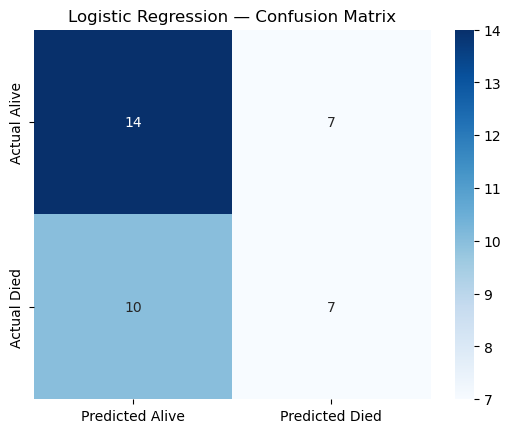

In [37]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Alive','Predicted Died'],
            yticklabels=['Actual Alive','Actual Died'])
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

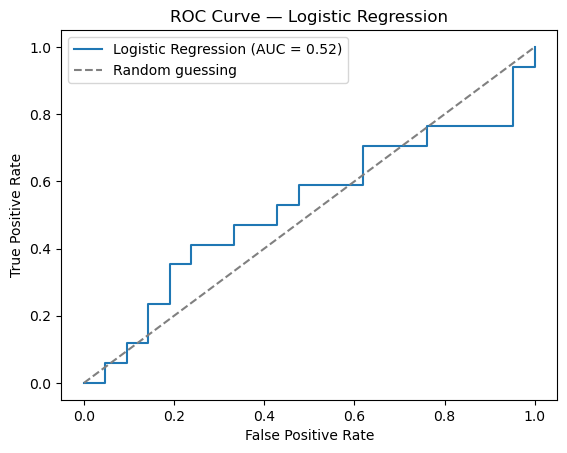

In [38]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_proba1)
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.show()

In [39]:
from sklearn.ensemble import RandomForestClassifier

model2 = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
model2.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, n_estimators=200, random_state=42)

In [41]:
y_pred2 = model2.predict(X_test)
y_proba2 = model2.predict_proba(X_test)[:, 1]

In [42]:
acc = accuracy_score(y_test, y_pred2)
prec = precision_score(y_test, y_pred2)
rec = recall_score(y_test, y_pred2)
f1 = f1_score(y_test, y_pred2)
auc = roc_auc_score(y_test, y_proba2)

print(f"Accuracy: {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall: {rec:.3f}")
print(f"F1-score: {f1:.3f}")
print(f"ROC-AUC: {auc:.3f}")

Accuracy: 0.579
Precision: 0.545
Recall: 0.353
F1-score: 0.429
ROC-AUC: 0.636


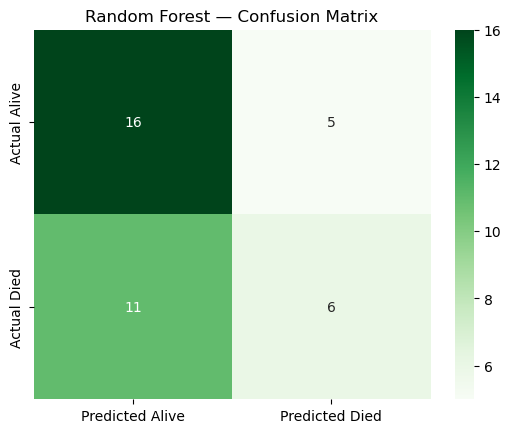

In [43]:
cm2 = confusion_matrix(y_test, y_pred2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Predicted Alive','Predicted Died'],
            yticklabels=['Actual Alive','Actual Died'])
plt.title("Random Forest — Confusion Matrix")
plt.show()

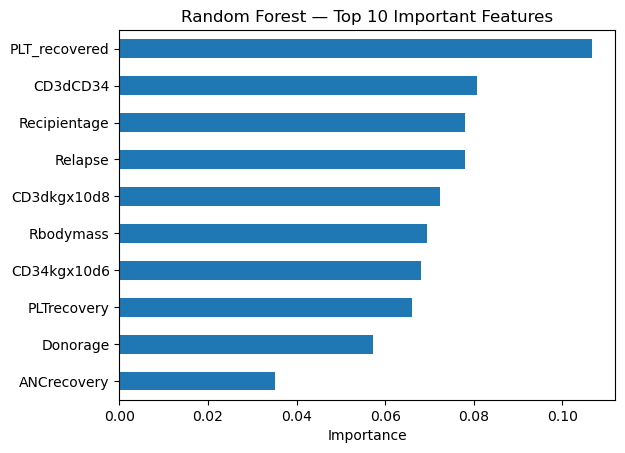

In [44]:
importances = pd.Series(model2.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Random Forest — Top 10 Important Features")
plt.xlabel("Importance")
plt.show()

In [45]:
print(accuracy_score(y_train, model2.predict(X_train)))

0.9463087248322147


In [46]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Logistic Regression': [0.553, 0.500, 0.412, 0.452, 0.521],
    'Random Forest': [0.579, 0.545, 0.353, 0.429, 0.636]
})
print(comparison)

      Metric  Logistic Regression  Random Forest
0   Accuracy                0.553          0.579
1  Precision                0.500          0.545
2     Recall                0.412          0.353
3   F1-score                0.452          0.429
4    ROC-AUC                0.521          0.636


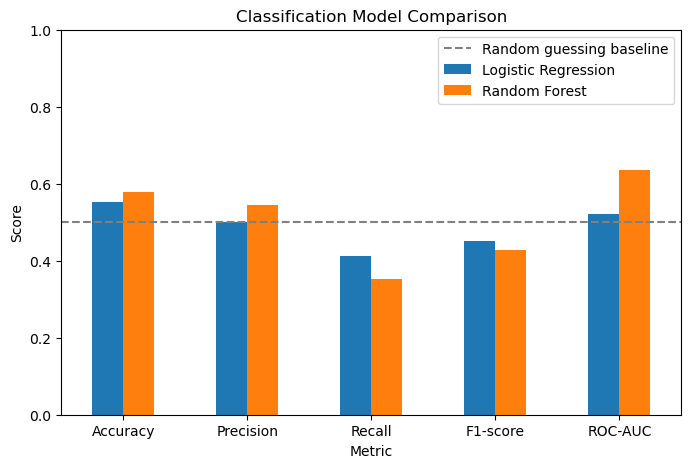

In [47]:
comparison.set_index('Metric').plot(kind='bar', figsize=(8,5))
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.axhline(0.5, color='gray', linestyle='--', label='Random guessing baseline')
plt.legend()
plt.show()

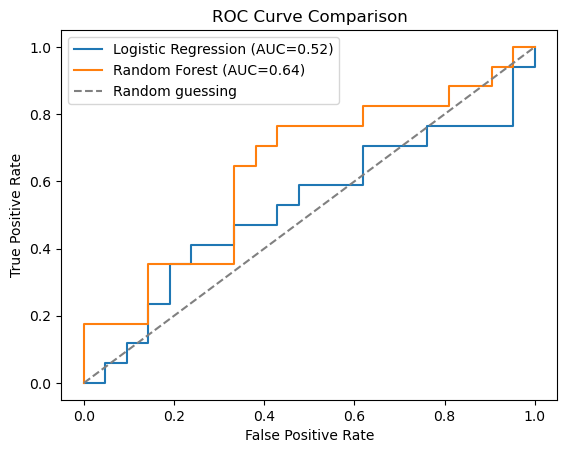

In [48]:
fpr1, tpr1, _ = roc_curve(y_test, y_proba1)
fpr2, tpr2, _ = roc_curve(y_test, y_proba2)

plt.plot(fpr1, tpr1, label=f"Logistic Regression (AUC={auc1:.2f})" if 'auc1' in dir() else "Logistic Regression (AUC=0.52)")
plt.plot(fpr2, tpr2, label="Random Forest (AUC=0.64)")
plt.plot([0,1],[0,1], linestyle='--', color='gray', label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [50]:
df_reg = pd.get_dummies(df, columns=['Disease'], prefix='Disease')

y_reg = df_reg['survival_time']
X_reg = df_reg.drop(columns=['survival_time', 'survival_status'])

print(X_reg.shape, y_reg.shape)
print(y_reg.describe().round(1))

(187, 39) (187,)
count     187.0
mean      938.7
std       849.6
min         6.0
25%       168.5
50%       676.0
75%      1604.0
max      3364.0
Name: survival_time, dtype: float64


In [51]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
print(Xr_train.shape, Xr_test.shape)

(149, 39) (38, 39)


In [52]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_impute_cols = ['Donorage','Recipientage','CD34kgx10d6','CD3dCD34','CD3dkgx10d8',
                    'Rbodymass','ANCrecovery','PLTrecovery','time_to_aGvHD_III_IV']
cat_impute_cols = ['RecipientABO','RecipientRh','ABOmatch','CMVstatus','DonorCMV',
                    'RecipientCMV','Antigen','Alel','extcGvHD']

num_imputer = SimpleImputer(strategy='median')
Xr_train[num_impute_cols] = num_imputer.fit_transform(Xr_train[num_impute_cols])
Xr_test[num_impute_cols] = num_imputer.transform(Xr_test[num_impute_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
Xr_train[cat_impute_cols] = cat_imputer.fit_transform(Xr_train[cat_impute_cols])
Xr_test[cat_impute_cols] = cat_imputer.transform(Xr_test[cat_impute_cols])

print(Xr_train.isna().sum().sum(), Xr_test.isna().sum().sum())

scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()
Xr_train_scaled[num_impute_cols] = scaler.fit_transform(Xr_train[num_impute_cols])
Xr_test_scaled[num_impute_cols] = scaler.transform(Xr_test[num_impute_cols])

0 0


In [53]:
from sklearn.linear_model import LinearRegression

reg1 = LinearRegression()
reg1.fit(Xr_train_scaled, yr_train)

LinearRegression()

In [54]:
yr_pred1 = reg1.predict(Xr_test_scaled)

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(yr_test, yr_pred1)
mse = mean_squared_error(yr_test, yr_pred1)
rmse = np.sqrt(mse)
r2 = r2_score(yr_test, yr_pred1)

print(f"MAE: {mae:.1f}")
print(f"MSE: {mse:.1f}")
print(f"RMSE: {rmse:.1f}")
print(f"R²: {r2:.3f}")

MAE: 810.1
MSE: 947818.1
RMSE: 973.6
R²: -0.029


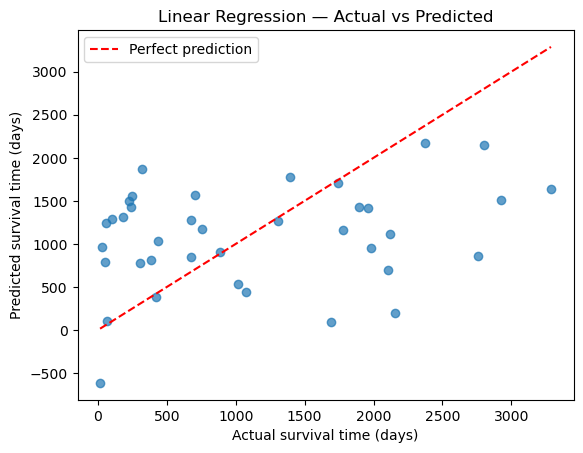

In [56]:
plt.scatter(yr_test, yr_pred1, alpha=0.7)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', label='Perfect prediction')
plt.xlabel("Actual survival time (days)")
plt.ylabel("Predicted survival time (days)")
plt.title("Linear Regression — Actual vs Predicted")
plt.legend()
plt.show()

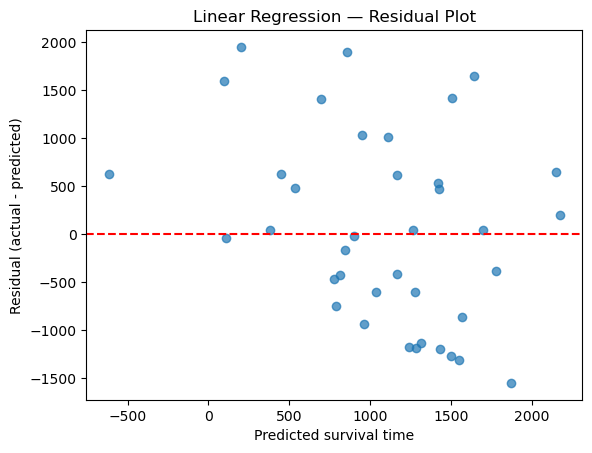

In [57]:
residuals = yr_test - yr_pred1
plt.scatter(yr_pred1, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted survival time")
plt.ylabel("Residual (actual - predicted)")
plt.title("Linear Regression — Residual Plot")
plt.show()

In [58]:
print(r2_score(yr_train, reg1.predict(Xr_train_scaled)))

0.3846967841726233


In [59]:
from sklearn.ensemble import RandomForestRegressor

reg2 = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42)
reg2.fit(Xr_train, yr_train)


RandomForestRegressor(max_depth=5, n_estimators=200, random_state=42)

In [60]:
yr_pred2 = reg2.predict(Xr_test)

In [61]:
mae = mean_absolute_error(yr_test, yr_pred2)
mse = mean_squared_error(yr_test, yr_pred2)
rmse = np.sqrt(mse)
r2 = r2_score(yr_test, yr_pred2)

print(f"MAE: {mae:.1f}")
print(f"MSE: {mse:.1f}")
print(f"RMSE: {rmse:.1f}")
print(f"R²: {r2:.3f}")

MAE: 762.2
MSE: 821020.9
RMSE: 906.1
R²: 0.109


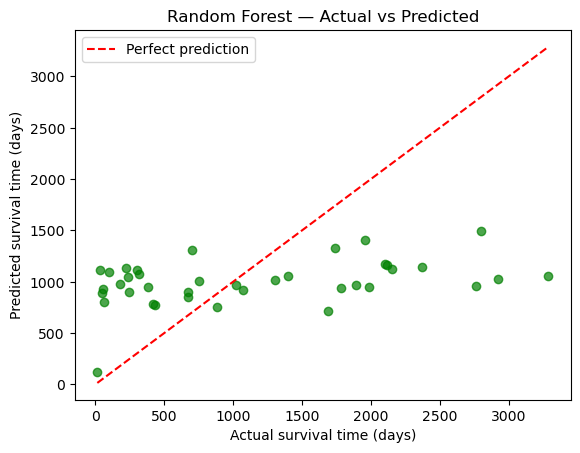

In [62]:
plt.scatter(yr_test, yr_pred2, alpha=0.7, color='green')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', label='Perfect prediction')
plt.xlabel("Actual survival time (days)")
plt.ylabel("Predicted survival time (days)")
plt.title("Random Forest — Actual vs Predicted")
plt.legend()
plt.show()

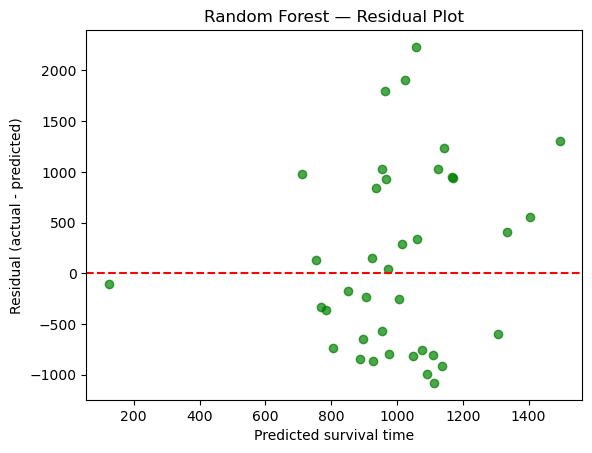

In [63]:
residuals2 = yr_test - yr_pred2
plt.scatter(yr_pred2, residuals2, alpha=0.7, color='green')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted survival time")
plt.ylabel("Residual (actual - predicted)")
plt.title("Random Forest — Residual Plot")
plt.show()

In [64]:
print(r2_score(yr_train, reg2.predict(Xr_train)))

0.5729679895916379


In [65]:
comparison_reg = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Linear Regression': [810.1, 947818.1, 973.6, -0.029],
    'Random Forest': [762.2, 821020.9, 906.1, 0.109]
})
print(comparison_reg)

  Metric  Linear Regression  Random Forest
0    MAE            810.100        762.200
1    MSE         947818.100     821020.900
2   RMSE            973.600        906.100
3     R²             -0.029          0.109


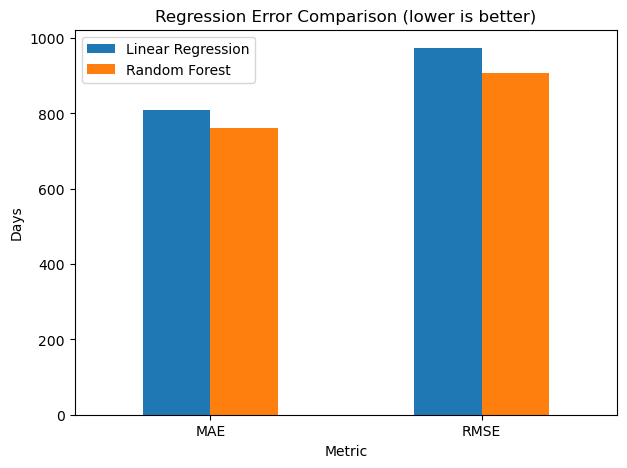

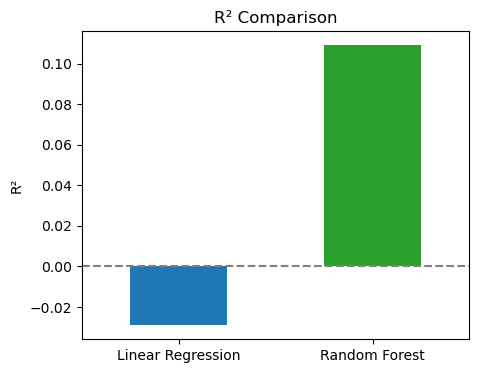

In [66]:
comparison_reg.set_index('Metric').loc[['MAE','RMSE']].plot(kind='bar', figsize=(7,5))
plt.title("Regression Error Comparison (lower is better)")
plt.ylabel("Days")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(5,4))
pd.Series({'Linear Regression': -0.029, 'Random Forest': 0.109}).plot(kind='bar', color=['tab:blue','tab:green'])
plt.axhline(0, color='gray', linestyle='--')
plt.title("R² Comparison")
plt.ylabel("R²")
plt.xticks(rotation=0)
plt.show()

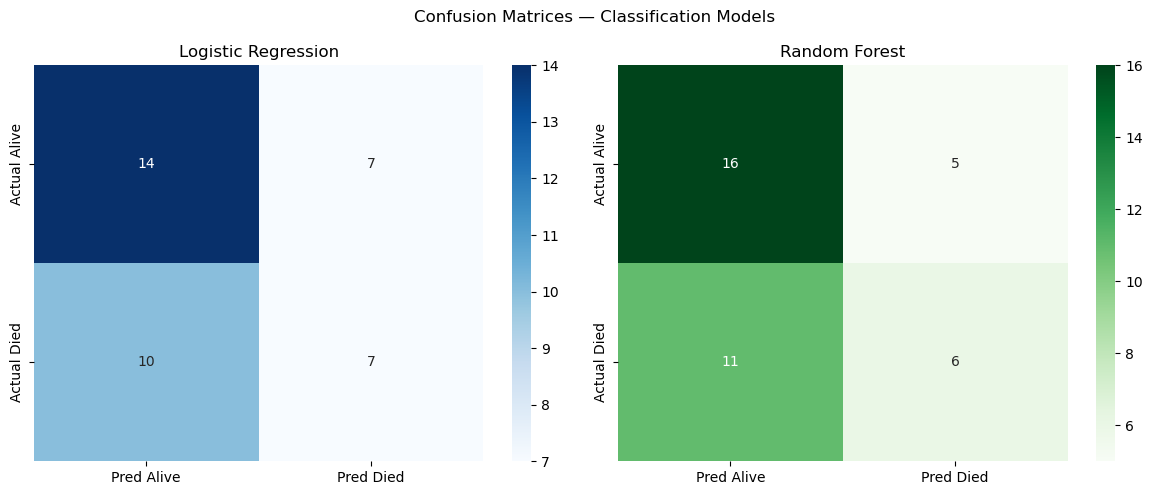

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm1 = confusion_matrix(y_test, y_pred1)
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Alive','Pred Died'], yticklabels=['Actual Alive','Actual Died'])
axes[0].set_title("Logistic Regression")

cm2 = confusion_matrix(y_test, y_pred2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Pred Alive','Pred Died'], yticklabels=['Actual Alive','Actual Died'])
axes[1].set_title("Random Forest")

plt.suptitle("Confusion Matrices — Classification Models")
plt.tight_layout()
plt.show()

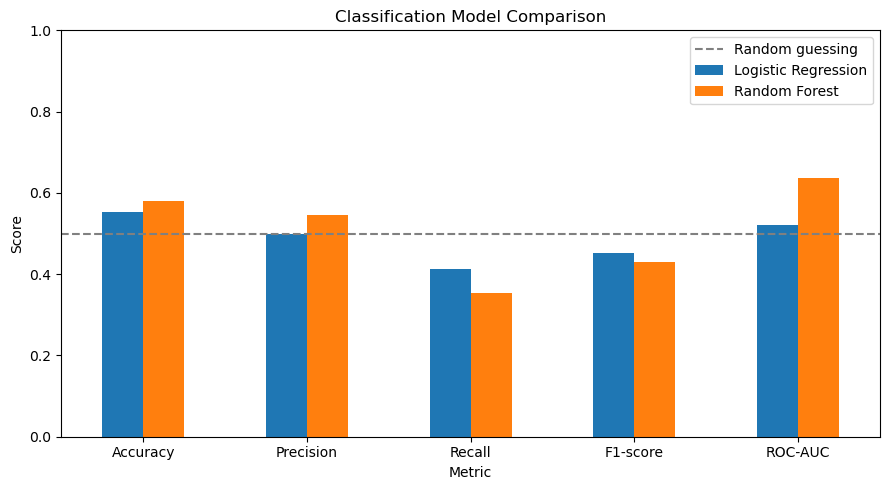

In [68]:
metrics_cls = pd.DataFrame({
    'Metric': ['Accuracy','Precision','Recall','F1-score','ROC-AUC'],
    'Logistic Regression': [0.553, 0.500, 0.412, 0.452, 0.521],
    'Random Forest': [0.579, 0.545, 0.353, 0.429, 0.636]
}).set_index('Metric')

metrics_cls.plot(kind='bar', figsize=(9,5))
plt.axhline(0.5, color='gray', linestyle='--', label='Random guessing')
plt.title("Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

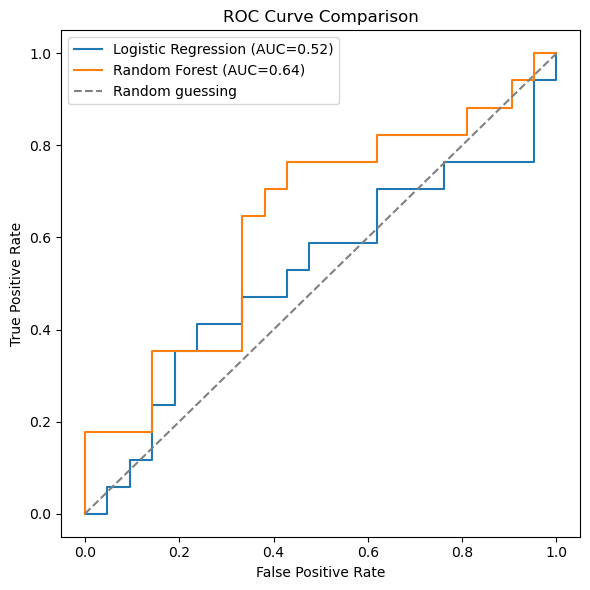

In [69]:
fpr1, tpr1, _ = roc_curve(y_test, y_proba1)
fpr2, tpr2, _ = roc_curve(y_test, y_proba2)

plt.figure(figsize=(6,6))
plt.plot(fpr1, tpr1, label="Logistic Regression (AUC=0.52)")
plt.plot(fpr2, tpr2, label="Random Forest (AUC=0.64)")
plt.plot([0,1],[0,1], linestyle='--', color='gray', label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()

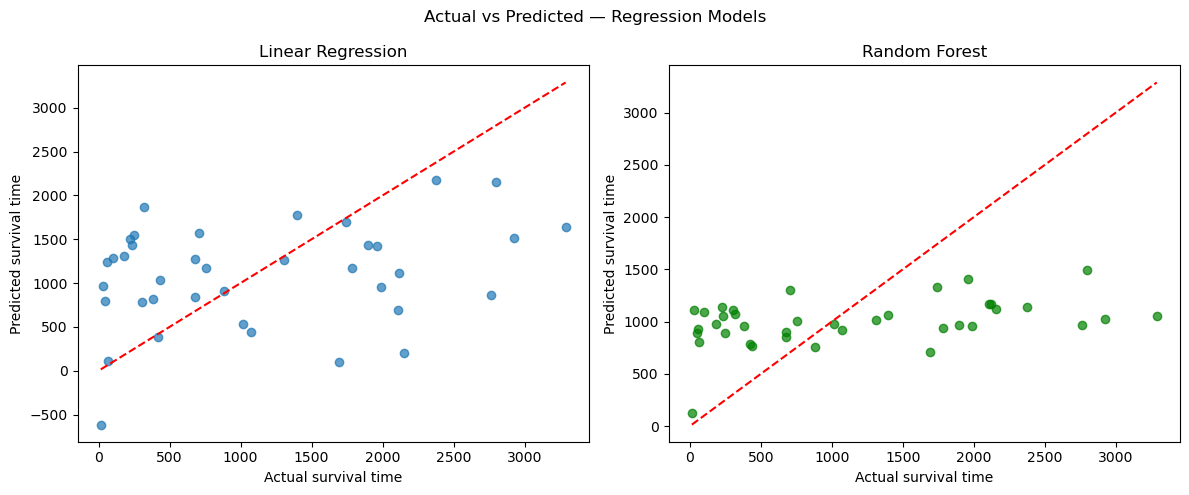

In [70]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(yr_test, yr_pred1, alpha=0.7)
axes[0].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual survival time")
axes[0].set_ylabel("Predicted survival time")

axes[1].scatter(yr_test, yr_pred2, alpha=0.7, color='green')
axes[1].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Actual survival time")
axes[1].set_ylabel("Predicted survival time")

plt.suptitle("Actual vs Predicted — Regression Models")
plt.tight_layout()
plt.show()

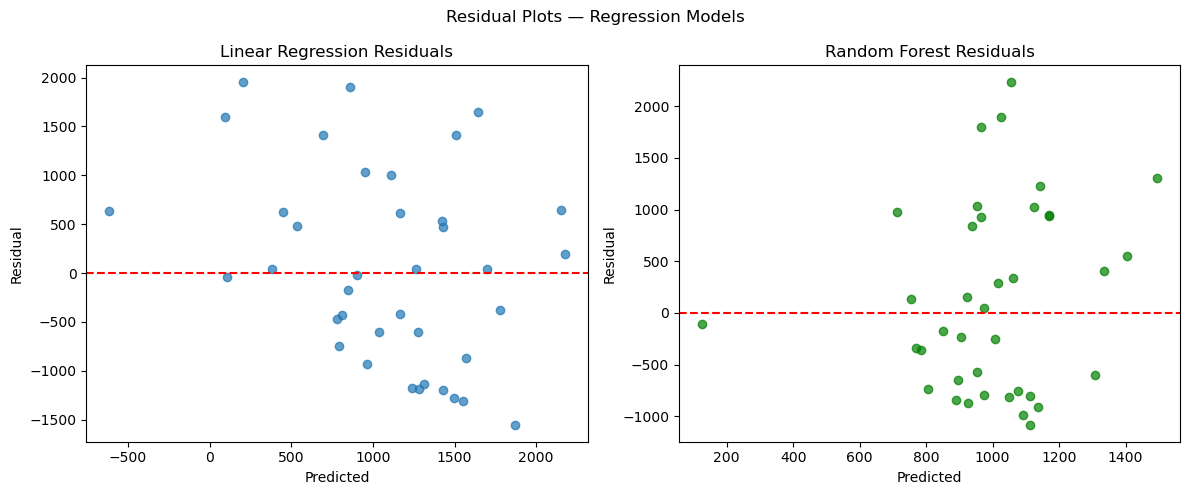

In [71]:
residuals1 = yr_test - yr_pred1
residuals2 = yr_test - yr_pred2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(yr_pred1, residuals1, alpha=0.7)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title("Linear Regression Residuals")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual")

axes[1].scatter(yr_pred2, residuals2, alpha=0.7, color='green')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title("Random Forest Residuals")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual")

plt.suptitle("Residual Plots — Regression Models")
plt.tight_layout()
plt.show()

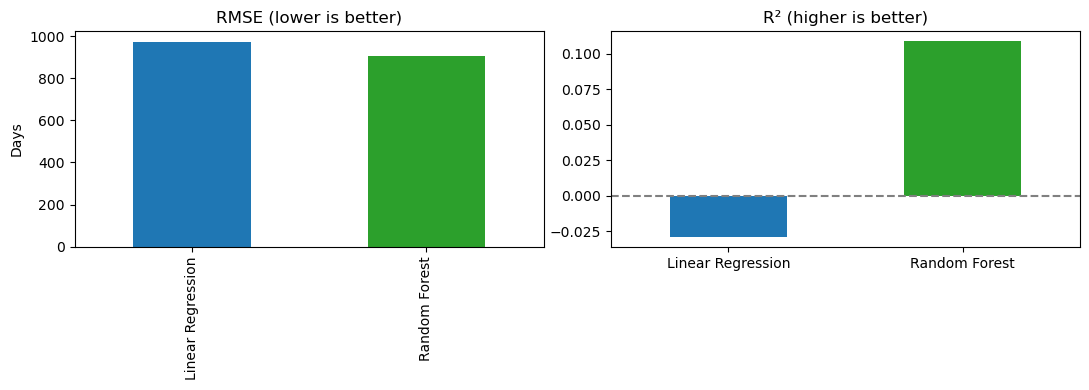

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))

pd.Series({'Linear Regression': 973.6, 'Random Forest': 906.1}).plot(kind='bar', ax=axes[0], color=['tab:blue','tab:green'])
axes[0].set_title("RMSE (lower is better)")
axes[0].set_ylabel("Days")

pd.Series({'Linear Regression': -0.029, 'Random Forest': 0.109}).plot(kind='bar', ax=axes[1], color=['tab:blue','tab:green'])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title("R² (higher is better)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [73]:
print("Logistic Regression — train:", accuracy_score(y_train, model1.predict(X_train_scaled)),
      "test:", accuracy_score(y_test, y_pred1))
print("Random Forest (cls) — train:", accuracy_score(y_train, model2.predict(X_train)),
      "test:", accuracy_score(y_test, y_pred2))
print("Linear Regression — train:", r2_score(yr_train, reg1.predict(Xr_train_scaled)),
      "test:", r2_score(yr_test, yr_pred1))
print("Random Forest (reg) — train:", r2_score(yr_train, reg2.predict(Xr_train)),
      "test:", r2_score(yr_test, yr_pred2))

Logistic Regression — train: 0.8523489932885906 test: 0.5526315789473685
Random Forest (cls) — train: 0.9463087248322147 test: 0.5789473684210527
Linear Regression — train: 0.3846967841726233 test: -0.028631593454244042
Random Forest (reg) — train: 0.5729679895916379 test: 0.10897666113126525


In [74]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_lr = cross_val_score(LogisticRegression(max_iter=1000, random_state=42), X_train_scaled, y_train, cv=skf, scoring='roc_auc')
cv_rf = cross_val_score(RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42), X_train, y_train, cv=skf, scoring='roc_auc')

print("Logistic Regression CV ROC-AUC:", cv_lr.mean().round(3), "±", cv_lr.std().round(3))
print("Random Forest CV ROC-AUC:", cv_rf.mean().round(3), "±", cv_rf.std().round(3))

Logistic Regression CV ROC-AUC: 0.794 ± 0.065
Random Forest CV ROC-AUC: 0.777 ± 0.071


In [75]:
from sklearn.model_selection import GridSearchCV

# Logistic Regression: tune regularization strength C
gs_lr = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                      {'C': [0.01, 0.1, 1, 10]}, cv=skf, scoring='roc_auc')
gs_lr.fit(X_train_scaled, y_train)
print("Best C:", gs_lr.best_params_, "| CV AUC:", round(gs_lr.best_score_, 3))

# Random Forest Classifier: tune depth and number of trees
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                      {'n_estimators': [100, 200], 'max_depth': [3, 5, 7]}, cv=skf, scoring='roc_auc')
gs_rf.fit(X_train, y_train)
print("Best RF params:", gs_rf.best_params_, "| CV AUC:", round(gs_rf.best_score_, 3))

# Random Forest Regressor: same idea
gs_rfr = GridSearchCV(RandomForestRegressor(random_state=42),
                       {'n_estimators': [100, 200], 'max_depth': [3, 5, 7]}, cv=kf, scoring='r2')
gs_rfr.fit(Xr_train, yr_train)
print("Best RF-Reg params:", gs_rfr.best_params_, "| CV R2:", round(gs_rfr.best_score_, 3))

Best C: {'C': 1} | CV AUC: 0.794
Best RF params: {'max_depth': 7, 'n_estimators': 200} | CV AUC: 0.794
Best RF-Reg params: {'max_depth': 3, 'n_estimators': 200} | CV R2: -0.116


In [76]:
best_lr, best_rf, best_rfr = gs_lr.best_estimator_, gs_rf.best_estimator_, gs_rfr.best_estimator_

print("Tuned LR  — test AUC:", round(roc_auc_score(y_test, best_lr.predict_proba(X_test_scaled)[:,1]), 3))
print("Tuned RF  — test AUC:", round(roc_auc_score(y_test, best_rf.predict_proba(X_test)[:,1]), 3))
print("Tuned RFR — test R2:", round(r2_score(yr_test, best_rfr.predict(Xr_test)), 3))

Tuned LR  — test AUC: 0.521
Tuned RF  — test AUC: 0.622
Tuned RFR — test R2: 0.073


In [77]:
final_results = pd.DataFrame({
    'Item': [
        'Dataset',
        'Total patients',
        'Train / Test split',
        '',
        'Classification target',
        'Classification Model 1',
        'Classification Model 2',
        '',
        'Regression target',
        'Regression Model 1',
        'Regression Model 2',
    ],
    'Details': [
        'Bone Marrow Transplant: Children (UCI ID 565)',
        '187 children',
        '149 train / 38 test (80/20, stratified for classification)',
        '',
        'survival_status (0 = alive, 1 = died)',
        'Logistic Regression',
        'Random Forest Classifier',
        '',
        'survival_time (days)',
        'Linear Regression',
        'Random Forest Regressor',
    ]
})
print(final_results.to_string(index=False))

                  Item                                                    Details
               Dataset              Bone Marrow Transplant: Children (UCI ID 565)
        Total patients                                               187 children
    Train / Test split 149 train / 38 test (80/20, stratified for classification)
                                                                                 
 Classification target                      survival_status (0 = alive, 1 = died)
Classification Model 1                                        Logistic Regression
Classification Model 2                                   Random Forest Classifier
                                                                                 
     Regression target                                       survival_time (days)
    Regression Model 1                                          Linear Regression
    Regression Model 2                                    Random Forest Regressor


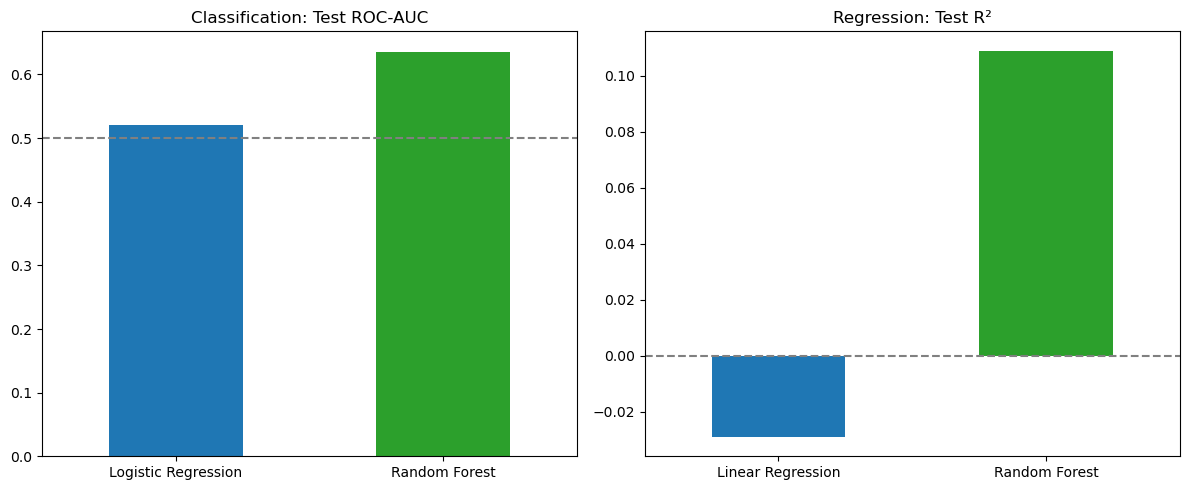

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
pd.Series({'Logistic Regression':0.521,'Random Forest':0.636}).plot(kind='bar', ax=axes[0], color=['tab:blue','tab:green'])
axes[0].set_title("Classification: Test ROC-AUC")
axes[0].axhline(0.5, color='gray', linestyle='--')

pd.Series({'Linear Regression':-0.029,'Random Forest':0.109}).plot(kind='bar', ax=axes[1], color=['tab:blue','tab:green'])
axes[1].set_title("Regression: Test R²")
axes[1].axhline(0, color='gray', linestyle='--')

for ax in axes: ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

In [85]:
print(df.groupby('PLT_recovered').agg(n=('survival_status','size'),
      died=('survival_status','sum'), median_days=('survival_time','median')))
print(pd.crosstab(df['Relapse'], df['survival_status']))
print(df.groupby('Disease')['survival_status'].agg(['size','mean']).round(2))

cd34_high = df['CD34kgx10d6'] > df['CD34kgx10d6'].median()
print(df.groupby(cd34_high).agg(n=('survival_status','size'),
      death_rate=('survival_status','mean'), median_days=('survival_time','median')))

                 n  died  median_days
PLT_recovered                        
0               17    17         42.0
1              170    68        836.5
survival_status   0   1
Relapse                
0                97  62
1                 5  23
              size  mean
Disease                 
ALL             68  0.44
AML             33  0.45
chronic         45  0.42
lymphoma         9  1.00
nonmalignant    32  0.38
              n  death_rate  median_days
CD34kgx10d6                             
False        94    0.553191        443.5
True         93    0.354839        964.0
